# 12 - Visualización avanzada con Matplotlib

Objetivos:
- Manejar la **API de pyplot** y el ciclo figura → ejes.
- Personalizar títulos, etiquetas, ticks, anotaciones y leyendas.
- Hacer **histogramas**, **boxplots**, **líneas** y **dispersión** con ajustes simples.
- Guardar figuras a archivo con `savefig`.


## 1. Dataset sintético

### ¿Qué es y para qué se usa?

Un dataset sintético es un conjunto de datos generado artificialmente para practicar sin depender de datos personales ni de descargas externas. Aquí permite construir ejemplos reproducibles de análisis y visualización con varias variables numéricas y categóricas.

### Parámetros principales

- **`rng`**: generador aleatorio con semilla fija para poder repetir el ejemplo.
- **`n`**: número de observaciones que tendrá el dataset.
- **`integers()`**: genera variables enteras, como `edad` o `satisfaccion`.
- **`normal()`**: genera valores continuos alrededor de una media y con una desviación dada.
- **`choice()`**: selecciona categorías para una variable cualitativa.

### Ejemplo

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 300
df = pd.DataFrame({
    "edad": rng.integers(18, 70, size=n),
    "ingresos": rng.normal(26000, 9000, size=n).round(2),
    "ciudad": rng.choice(["Cádiz","Sevilla","Málaga","Córdoba"], size=n),
    "satisfaccion": rng.integers(1, 6, size=n),
})
df.head()

,edad,ingresos,ciudad,satisfaccion
0,62,25019.77,Córdoba,5
1,51,18766.41,Sevilla,4
2,44,35721.47,Málaga,5
3,32,23401.10,Cádiz,1
4,34,26751.28,Málaga,3


## 2. Histograma

### ¿Qué es y para qué se usa?

Un histograma agrupa los valores de una variable numérica en intervalos y cuenta cuántas observaciones caen en cada uno. Se usa para estudiar la distribución, la concentración y la dispersión de los ingresos.

### Parámetros principales de `plt.hist()`

- **`x`**: valores numéricos que se distribuyen en el gráfico.
- **`bins`**: número de intervalos o límites de los intervalos.
- **`range`**: límites mínimo y máximo que se mostrarán.
- **`density`**: si es `True`, normaliza el histograma para mostrar densidad.
- **`alpha`**, **`color`**: transparencia y color de las barras.

### Ejemplo

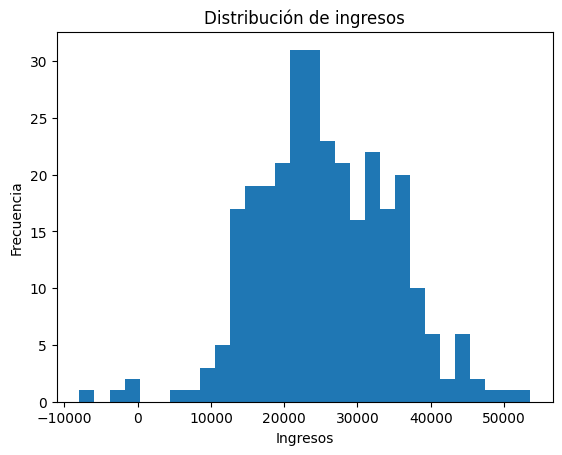

In [2]:
plt.figure()
plt.hist(df["ingresos"].dropna(), bins=30)
plt.title("Distribución de ingresos")
plt.xlabel("Ingresos"); plt.ylabel("Frecuencia")
plt.show()

## 3. Boxplot por categoría

### ¿Qué es y para qué se usa?

Un boxplot resume una distribución mediante la mediana, los cuartiles y los valores extremos. Se usa aquí para comparar la dispersión de los ingresos entre ciudades y detectar posibles valores atípicos.

### Parámetros principales

- **`column`**: variable numérica que se representa.
- **`by`**: variable categórica que define los grupos.
- **`grid`**: muestra u oculta la cuadrícula.
- **`vert`**: orienta las cajas vertical u horizontalmente en `plt.boxplot()`.
- **`showmeans`**, **`showfliers`**: muestra la media y los valores atípicos.

### Ejemplo

<Figure size 640x480 with 0 Axes>

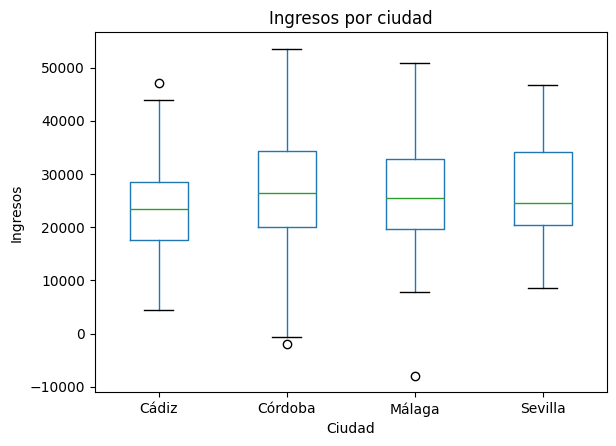

In [3]:
plt.figure()
df.boxplot(column="ingresos", by="ciudad", grid=False)
plt.title("Ingresos por ciudad")
plt.suptitle("")
plt.xlabel("Ciudad"); plt.ylabel("Ingresos")
plt.show()

## 4. Dispersión con recta de ajuste (polyfit)

### ¿Qué es y para qué se usa?

Un gráfico de dispersión representa cada observación como un punto y permite estudiar la relación entre dos variables numéricas. Una recta de ajuste resume la tendencia lineal y ayuda a valorar si existe una relación aproximada entre edad e ingresos.

### Parámetros principales

- **`x`, `y`**: variables numéricas que ocupan los ejes.
- **`alpha`**: transparencia de los puntos, útil cuando se solapan.
- **`s`**: tamaño de los puntos.
- **`color`**: color de los puntos o de la recta.
- **`np.polyfit(x, y, 1)`**: calcula los coeficientes de un ajuste lineal de grado 1.
- **`linewidth`**: grosor de la recta de ajuste.

### Ejemplo

In [ ]:
x = df["edad"].values
y = df["ingresos"].values

# Ajuste lineal y = a*x + b
a, b = np.polyfit(x, y, 1)

plt.figure()
plt.scatter(x, y, alpha=0.6)
plt.plot(np.sort(x), a*np.sort(x) + b, linewidth=2)
plt.title("Edad vs Ingresos con ajuste lineal")
plt.xlabel("Edad"); plt.ylabel("Ingresos")
plt.show()

## 5. Anotaciones y guardado

### ¿Qué son y para qué se usan?

Las anotaciones añaden contexto al gráfico, por ejemplo, señalando la media o un valor relevante. El guardado permite reutilizar la figura en un informe o presentación sin depender del notebook.

### Parámetros principales

- **`plt.axvline()`**: dibuja una línea vertical de referencia.
- **`plt.text(x, y, texto)`**: coloca una etiqueta en unas coordenadas.
- **`plt.tight_layout()`**: ajusta automáticamente los márgenes.
- **`fname`**: ruta y nombre del archivo en `plt.savefig()`.
- **`dpi`**: resolución de la imagen exportada.
- **`bbox_inches='tight'`**: evita recortes en los bordes.

### Ejemplo

In [ ]:
media_ing = df["ingresos"].mean()

plt.figure()
plt.hist(df["ingresos"], bins=25)
plt.axvline(media_ing, linestyle="--")
plt.text(media_ing, plt.ylim()[1]*0.9, f"media = {media_ing:.0f}")
plt.title("Histograma con línea de media")
plt.xlabel("Ingresos"); plt.ylabel("Frecuencia")
plt.tight_layout()
out_png = "/mnt/data/fig_hist_ingresos.png"
plt.savefig(out_png, dpi=120)
out_png

## 📝 Ejercicios

1) Repite el histograma de `satisfaccion` con 5 bins y añade título y etiquetas.  
2) Haz un boxplot de `satisfaccion` por `ciudad`.  
3) Crea una gráfica de líneas con la **media móvil** de `ingresos` (ventana 10) y guarda la figura.
